# multi-class classification problem using ANN

In [19]:
import numpy as np
import pandas as pd

import tensorflow 
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input, Flatten

In [2]:
(X_train, y_train),(X_test,y_test) = keras.datasets.mnist.load_data() 

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [3]:
X_train.shape

(60000, 28, 28)

In [5]:
y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

# we can see, data gulo dekhte kmn. karon eikhane datagulo numpy array te ase

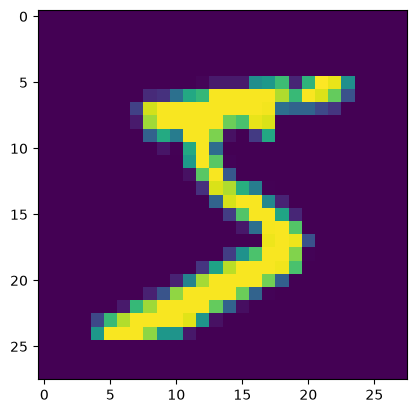

In [4]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0])

# Note: DEEP Learning e, dataset er values joto similar range e thake, weight thik toto sohoje ber kore niya asa jai/ ba ase. and convergence fast hoy

In [15]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [16]:
X_train = X_train/255
X_test = X_test/255

In [18]:
X_train[0][6]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.11764706, 0.14117647,
       0.36862745, 0.60392157, 0.66666667, 0.99215686, 0.99215686,
       0.99215686, 0.99215686, 0.99215686, 0.88235294, 0.6745098 ,
       0.99215686, 0.94901961, 0.76470588, 0.25098039, 0.        ,
       0.        , 0.        , 0.        ])

# flaten layer
- high dimensional data ke lower dimension e niya ase.
- amader 28*28 pixel data ke jeita image er - eita ke 1D te ante hobe jei hocche 
- 28*28 = 784. ei 784 hocche 1D

In [36]:
model = Sequential()

# Define input: 28*28 features
model.add(Input(shape=(28, 28)))

# convert 2D into 1D: 28*28=784
model.add(Flatten())

# hidden layer
model.add(Dense(128,activation='relu'))
model.add(Dense(32,activation='relu'))

# Outpur layer
model.add(Dense(10,activation='softmax'))

In [37]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,938 (409.91 KB)

 Trainable params: 104,938 (409.91 KB)

 Non-trainable params: 0 (0.00 B)

# Note: output layer e jodi 1 er beshi node or layer thake . tahole activation e "Softmax" use korbo. eita valo perform kore

# compile

Note: spare_categorical_crossentropy use korle encoding er dorkar hoina. but categorical_crossentropy use korle dorkar hoy

In [38]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='Adam')

In [40]:
history = model.fit(X_train, y_train, epochs=50, validation_split=0.2)

Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0062 - val_loss: 0.1713
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0071 - val_loss: 0.1826
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0080 - val_loss: 0.1780
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0050 - val_loss: 0.2170
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0077 - val_loss: 0.1900
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0049 - val_loss: 0.1760
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0077 - val_loss: 0.1728
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0048 - val_loss: 0.1890
Epoch 9/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0076 - val_loss: 0.1908
Epoch 10/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0070 - val_loss: 0.1965
Epoch 11/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0056 - val_loss: 0.1751
Epoch 12/50
1500/1500 ━━━━━━━━

In [41]:
y_prob = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [42]:
y_pred = y_prob.argmax(axis=1)
y_pred

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [43]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9792

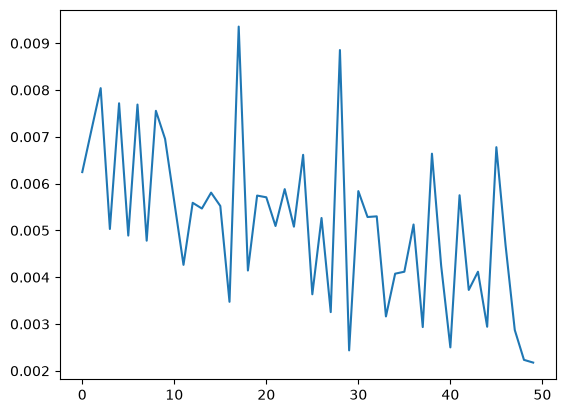

In [44]:
plt.plot(history.history['loss'])

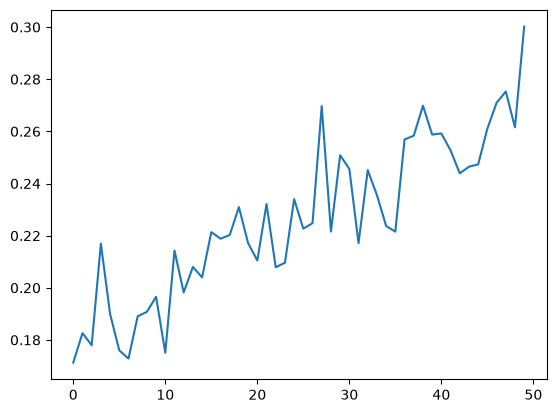

In [45]:
plt.plot(history.history['val_loss'])

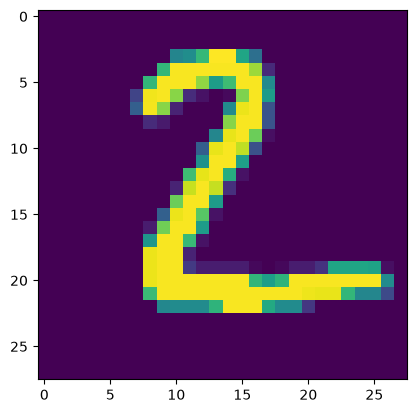

In [52]:
plt.imshow(X_test[1])

In [53]:
model.predict(X_test[1].reshape(1,28,28)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step


array([2])